# Superstore Sales Analysis

**Business question:** Which products, categories, regions, customer segments, and time periods drive the most sales, and where are the growth opportunities?

**Steps:** 1) Load data 2) Clean data 3) Answer 5 business questions with charts 4) Recommendations

## 1. Import libraries

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Folder where charts will be saved
os.makedirs("../images", exist_ok=True)

## 2. Load the data

In [3]:
df = pd.read_csv("superstore.csv", encoding="latin-1")

# Clean column names (remove extra spaces)
df.columns = df.columns.str.strip()

print("Rows, Columns:", df.shape)
print(df.columns.tolist())
df.head()

Rows, Columns: (9800, 18)
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales']


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


## 3. Data cleaning

In [4]:
df.info()
print("\nMissing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   str    
 2   Order Date     9800 non-null   str    
 3   Ship Date      9800 non-null   str    
 4   Ship Mode      9800 non-null   str    
 5   Customer ID    9800 non-null   str    
 6   Customer Name  9800 non-null   str    
 7   Segment        9800 non-null   str    
 8   Country        9800 non-null   str    
 9   City           9800 non-null   str    
 10  State          9800 non-null   str    
 11  Postal Code    9789 non-null   float64
 12  Region         9800 non-null   str    
 13  Product ID     9800 non-null   str    
 14  Category       9800 non-null   str    
 15  Sub-Category   9800 non-null   str    
 16  Product Name   9800 non-null   str    
 17  Sales          9800 non-null   float64
dtypes: float64(2), int6

In [5]:
# Remove duplicates
df = df.drop_duplicates()

# Convert dates (this dataset uses day/month/year format)
df["Order Date"] = pd.to_datetime(df["Order Date"], dayfirst=True, errors="coerce")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], dayfirst=True, errors="coerce")
print("Invalid Order Dates:", df["Order Date"].isnull().sum())

# Drop rows where the date could not be read
df = df.dropna(subset=["Order Date"])

# Fill missing Postal Code if the column has gaps (not used for analysis)
if "Postal Code" in df.columns:
    df["Postal Code"] = df["Postal Code"].fillna(0)

# New columns for time analysis
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Month Name"] = df["Order Date"].dt.month_name()

# Days taken to ship
df["Shipping Days"] = (df["Ship Date"] - df["Order Date"]).dt.days

print("Cleaned shape:", df.shape)

Invalid Order Dates: 0
Cleaned shape: (9800, 22)


**Cleaning notes:** removed duplicate rows, converted `Order Date` and `Ship Date` to datetime (day-first format), dropped rows with invalid dates, and added `Year`, `Month`, and `Shipping Days` columns. *(Edit this to match what you actually found.)*

## 4. Overall summary

In [6]:
total_sales = df["Sales"].sum()
orders = df["Order ID"].nunique()
customers = df["Customer ID"].nunique()

print(f"Total Sales:            ${total_sales:,.0f}")
print(f"Total Orders:           {orders:,}")
print(f"Unique Customers:       {customers:,}")
print(f"Average Order Value:    ${total_sales/orders:,.2f}")

Total Sales:            $2,261,537
Total Orders:           4,922
Unique Customers:       793
Average Order Value:    $459.48


## Q1. Which categories and sub-categories generate the most sales?

Category
Technology         827455.8730
Furniture          728658.5757
Office Supplies    705422.3340
Name: Sales, dtype: float64


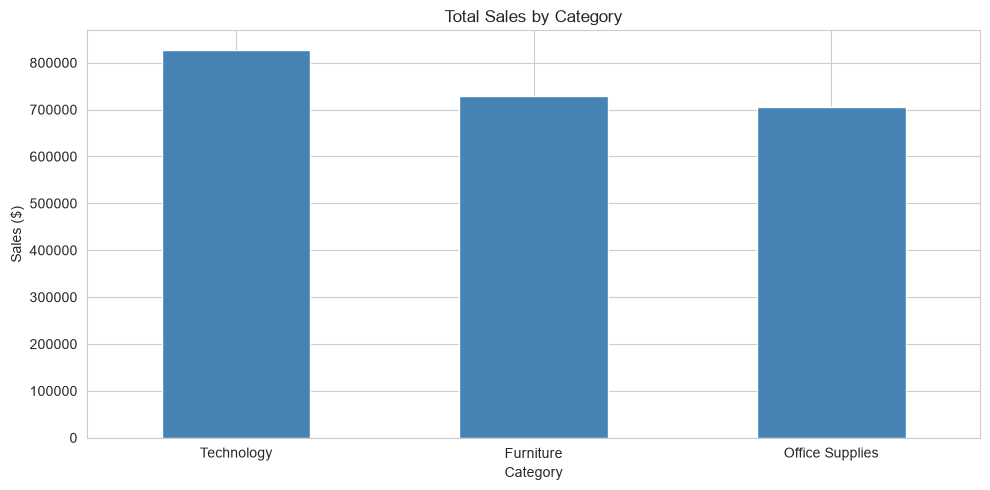

In [7]:
cat = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)
print(cat)

cat.plot(kind="bar", color="steelblue")
plt.title("Total Sales by Category")
plt.ylabel("Sales ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../images/q1_category.png", dpi=150)
plt.show()

Sub-Category
Fasteners        3001.9600
Labels          12347.7260
Envelopes       16128.0460
Art             26705.4100
Supplies        46420.3080
Paper           76828.3040
Furnishings     89212.0180
Appliances     104618.4030
Bookcases      113813.1987
Copiers        146248.0940
Accessories    164186.7000
Machines       189238.6310
Binders        200028.7850
Tables         202810.6280
Storage        219343.3920
Chairs         322822.7310
Phones         327782.4480
Name: Sales, dtype: float64


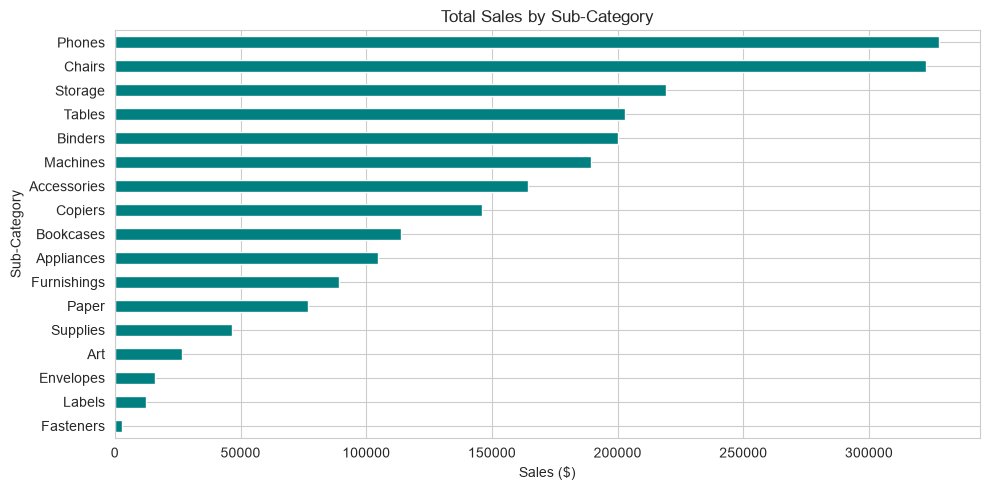

In [8]:
sub = df.groupby("Sub-Category")["Sales"].sum().sort_values()
print(sub)

sub.plot(kind="barh", color="teal")
plt.title("Total Sales by Sub-Category")
plt.xlabel("Sales ($)")
plt.tight_layout()
plt.savefig("../images/q1_subcategory.png", dpi=150)
plt.show()

**Insight:** *(Write 1-2 sentences. Example: Technology is the top category, and Phones and Chairs are the top sub-categories.)*

## Q2. Which regions and states perform best?

Region
South      389151.4590
Central    492646.9132
East       669518.7260
West       710219.6845
Name: Sales, dtype: float64


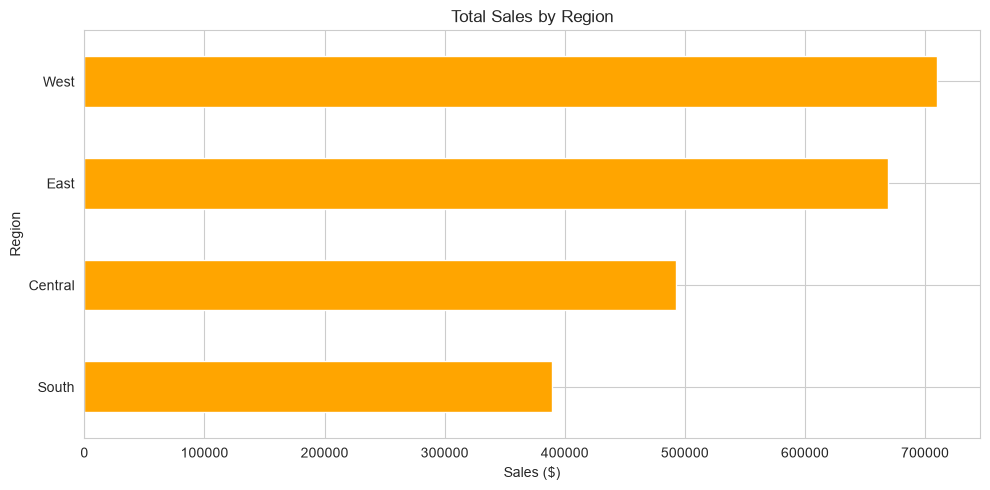

In [9]:
region = df.groupby("Region")["Sales"].sum().sort_values()
print(region)

region.plot(kind="barh", color="orange")
plt.title("Total Sales by Region")
plt.xlabel("Sales ($)")
plt.tight_layout()
plt.savefig("../images/q2_region.png", dpi=150)
plt.show()

State
California      446306.4635
New York        306361.1470
Texas           168572.5322
Washington      135206.8500
Pennsylvania    116276.6500
Florida          88436.5320
Illinois         79236.5170
Michigan         76136.0740
Ohio             75130.3500
Virginia         70636.7200
Name: Sales, dtype: float64


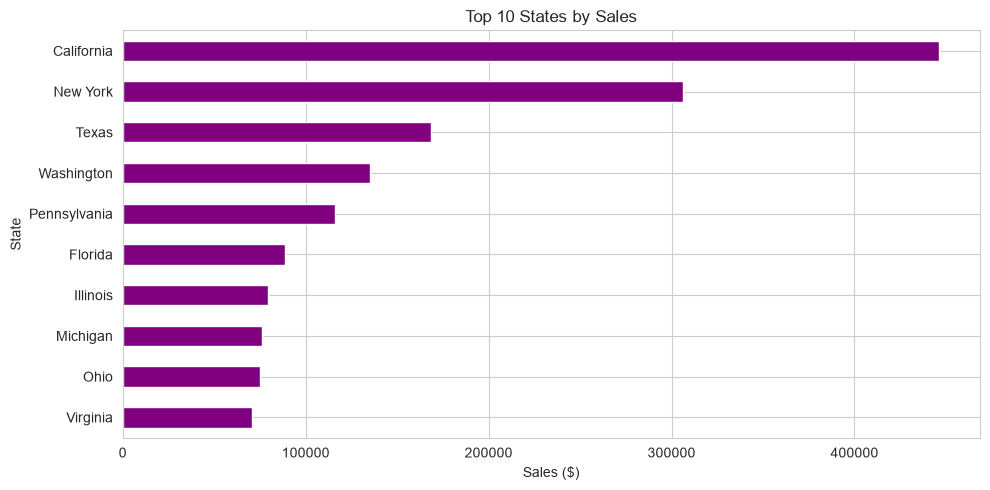

In [10]:
state = df.groupby("State")["Sales"].sum().sort_values(ascending=False).head(10)
print(state)

state.sort_values().plot(kind="barh", color="purple")
plt.title("Top 10 States by Sales")
plt.xlabel("Sales ($)")
plt.tight_layout()
plt.savefig("../images/q2_top_states.png", dpi=150)
plt.show()

**Insight:** *(Which region is best and which is weakest? Which states lead?)*

## Q3. How do sales change over time?

Year
2015    479856.2081
2016    459436.0054
2017    600192.5500
2018    722052.0192
Name: Sales, dtype: float64


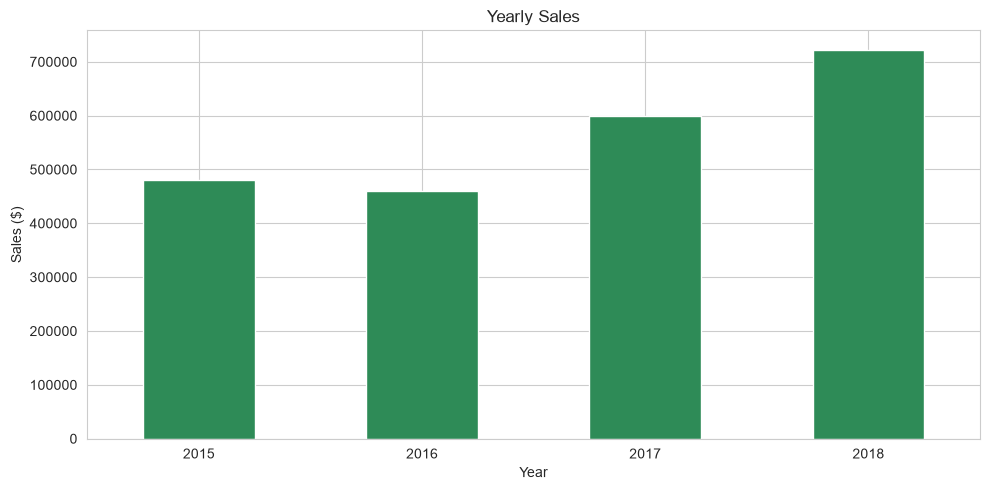

In [11]:
yearly = df.groupby("Year")["Sales"].sum()
print(yearly)

yearly.plot(kind="bar", color="seagreen")
plt.title("Yearly Sales")
plt.ylabel("Sales ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../images/q3_yearly.png", dpi=150)
plt.show()

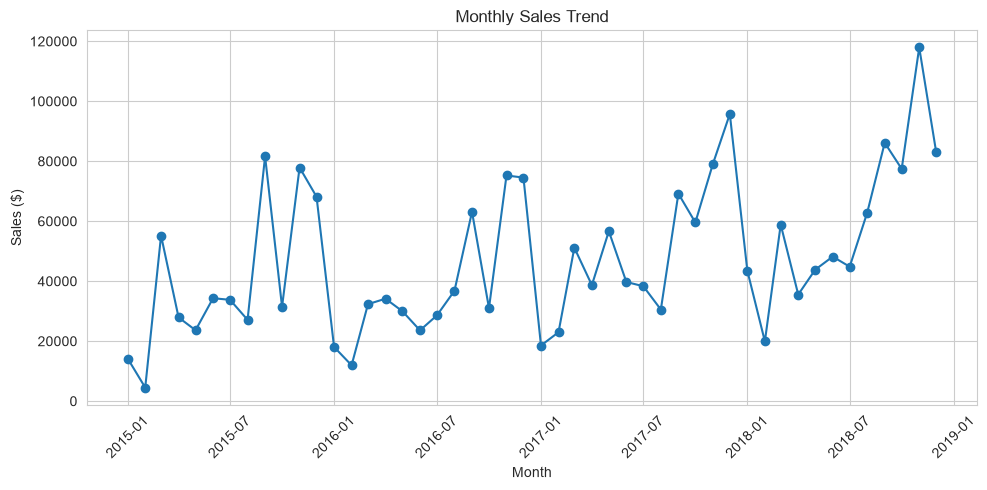

In [12]:
monthly = df.groupby(df["Order Date"].dt.to_period("M"))["Sales"].sum()
monthly.index = monthly.index.to_timestamp()

plt.plot(monthly.index, monthly.values, marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales ($)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../images/q3_monthly_trend.png", dpi=150)
plt.show()

In [13]:
# Which calendar months are strongest overall?
month_order = ["January","February","March","April","May","June","July",
               "August","September","October","November","December"]
by_month = df.groupby("Month Name")["Sales"].sum().reindex(month_order)
print(by_month)

Month Name
January       94291.6296
February      59371.1154
March        197573.5872
April        136283.0006
May          154086.7237
June         145837.5233
July         145535.6890
August       157315.9270
September    300103.4117
October      199496.2947
November     350161.7110
December     321480.1695
Name: Sales, dtype: float64


**Insight:** *(Is there a seasonal peak, e.g., Nov/Dec? Are sales growing year over year?)*

## Q4. Who are the top products and top customers?

Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: Sales, dtype: float64


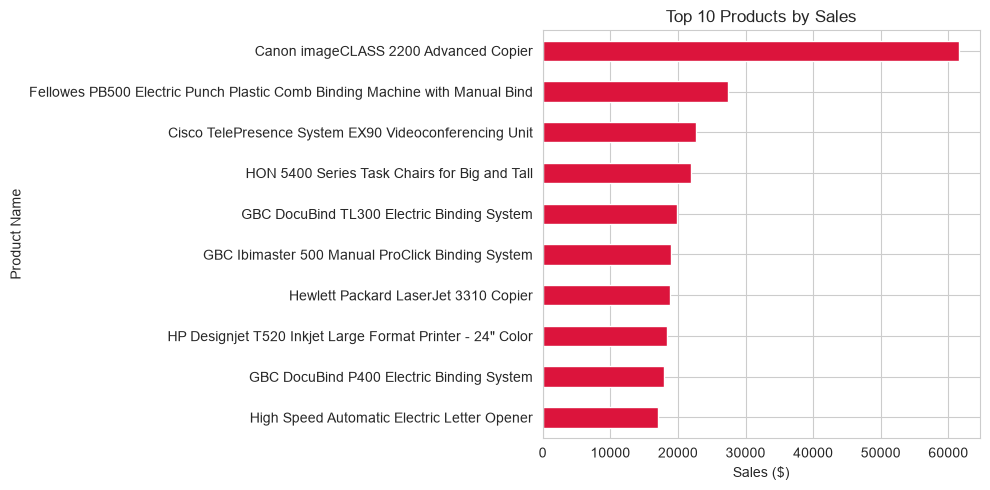

In [14]:
top_products = df.groupby("Product Name")["Sales"].sum().nlargest(10)
print(top_products)

top_products.sort_values().plot(kind="barh", color="crimson")
plt.title("Top 10 Products by Sales")
plt.xlabel("Sales ($)")
plt.tight_layout()
plt.savefig("../images/q4_top_products.png", dpi=150)
plt.show()

Customer Name
Sean Miller           25043.050
Tamara Chand          19052.218
Raymond Buch          15117.339
Tom Ashbrook          14595.620
Adrian Barton         14473.571
Ken Lonsdale          14175.229
Sanjit Chand          14142.334
Hunter Lopez          12873.298
Sanjit Engle          12209.438
Christopher Conant    12129.072
Name: Sales, dtype: float64


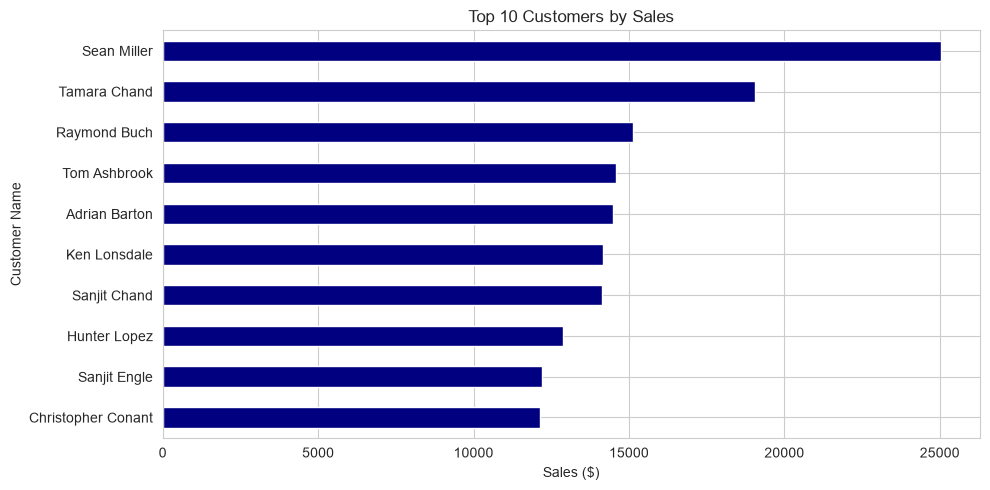

In [15]:
top_customers = df.groupby("Customer Name")["Sales"].sum().nlargest(10)
print(top_customers)

top_customers.sort_values().plot(kind="barh", color="navy")
plt.title("Top 10 Customers by Sales")
plt.xlabel("Sales ($)")
plt.tight_layout()
plt.savefig("../images/q4_top_customers.png", dpi=150)
plt.show()

**Insight:** *(Do a few products or customers contribute a large share of sales?)*

## Q5. Which customer segments and ship modes matter most?

Segment
Consumer       1.148061e+06
Corporate      6.884941e+05
Home Office    4.249822e+05
Name: Sales, dtype: float64
Segment
Consumer       50.8
Corporate      30.4
Home Office    18.8
Name: Sales, dtype: float64


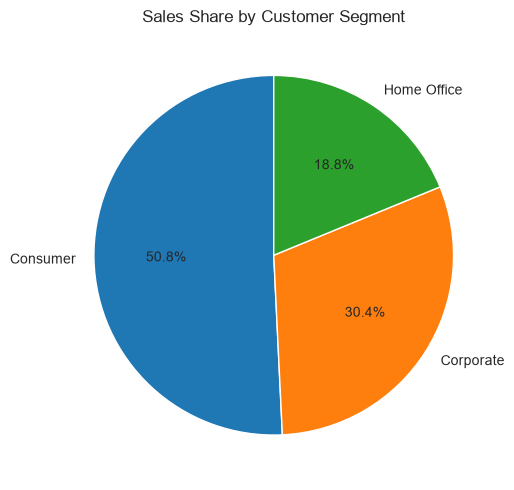

In [16]:
seg = df.groupby("Segment")["Sales"].sum().sort_values(ascending=False)
print(seg)
print((seg / seg.sum() * 100).round(1))

seg.plot(kind="pie", autopct="%1.1f%%", startangle=90)
plt.title("Sales Share by Customer Segment")
plt.ylabel("")
plt.tight_layout()
plt.savefig("../images/q5_segment.png", dpi=150)
plt.show()

Ship Mode
Standard Class    1.340831e+06
Second Class      4.499142e+05
First Class       3.455723e+05
Same Day          1.252190e+05
Name: Sales, dtype: float64


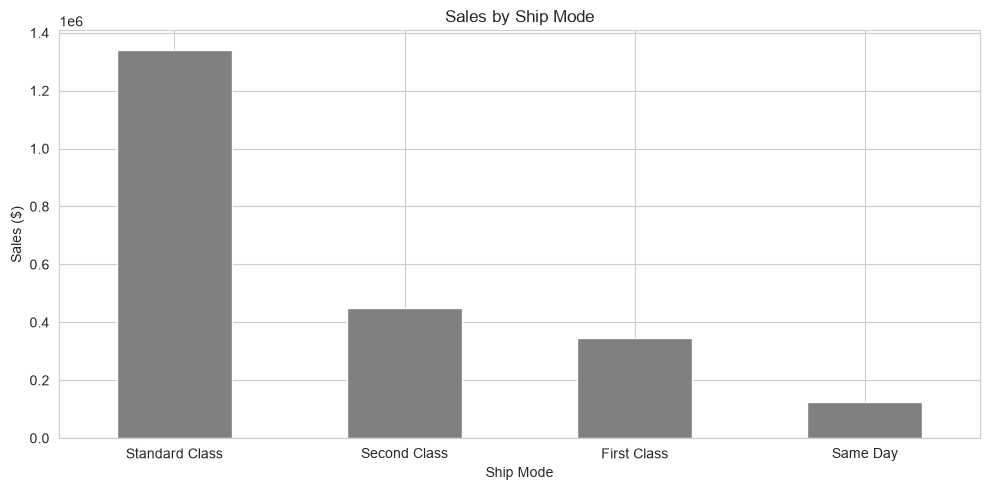

In [17]:
ship = df.groupby("Ship Mode")["Sales"].sum().sort_values(ascending=False)
print(ship)

ship.plot(kind="bar", color="gray")
plt.title("Sales by Ship Mode")
plt.ylabel("Sales ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../images/q5_ship_mode.png", dpi=150)
plt.show()

**Insight:** *(Which segment brings the most sales? Which ship mode is preferred?)*

## Bonus: Category x Region heatmap

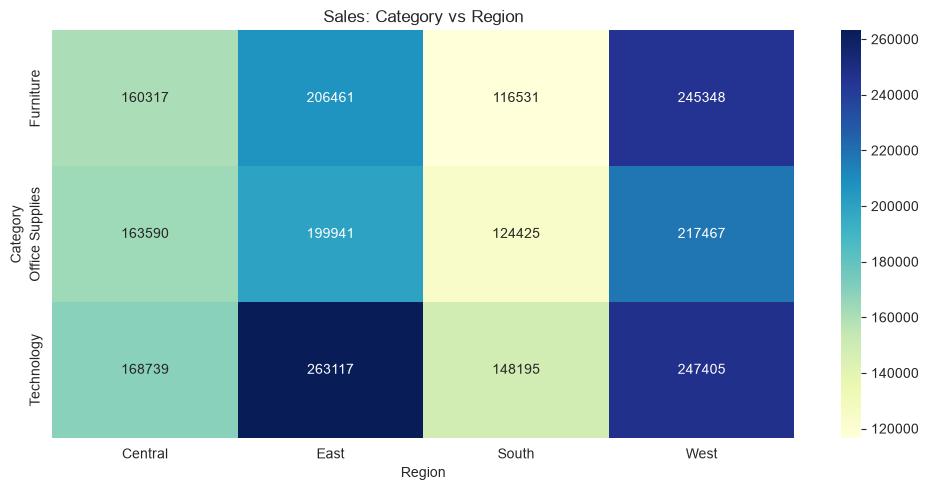

In [18]:
pivot = df.pivot_table(values="Sales", index="Category", columns="Region", aggfunc="sum")
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="YlGnBu")
plt.title("Sales: Category vs Region")
plt.tight_layout()
plt.savefig("../images/bonus_heatmap.png", dpi=150)
plt.show()

## 5. Key Findings & Recommendations

**Findings** *(replace with your real results)*
1. ...
2. ...
3. ...

**Recommendations**
1. Increase marketing and stock for the top-selling category and sub-categories.
2. Invest more in the strongest region and study why the weakest region lags.
3. Prepare inventory and campaigns ahead of the seasonal sales peak.
4. Build loyalty offers for top customers and the leading segment.